<a href="https://colab.research.google.com/github/AISIRIJ/Agentic_AI/blob/main/Classification_Models_Exercise_Aisiri_J.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classification Models: From Binary Diagnosis to Multiclass Prediction

---

> ### 📋 Practice Exercise. Not Graded.
> This is a **practice assignment** for self-assessment. The marks shown throughout are **indicative only**. They tell you where to spend your effort and where you might need more practice. **None of these marks count towards your final grade.**
>
> Attempt every section. Compare your results. Revisit what trips you up.

---

## What You Will Build

Two classifiers, two datasets, one progression from simple to complex.

| Part | Dataset | Task | Primary Metric |
|------|---------|------|----------------|
| **Part 1** | Breast Cancer (sklearn) | Binary: Malignant vs Benign | Recall (Sensitivity) |
| **Part 2** | Wine (sklearn) | Multiclass: 3 wine cultivars | Macro-averaged F1-Score |

**Indicative Marks: 100** (Part 1: 55 | Part 2: 45)

### Before You Start
- Complete all cells marked with `# TODO`.
- Markdown cells marked **[Your Answer]** need written responses. Don't skip them.
- Run `Runtime > Restart and run all` before reviewing. The notebook should execute top to bottom without errors.
- Use `random_state=42` wherever a function accepts it. This keeps your results reproducible.


---
# PART 1: Binary Classification, Breast Cancer Prediction

## Context

Early detection of malignant tumours saves lives. In this part, you will build classifiers that predict whether a breast tumour is **malignant** or **benign** based on features computed from cell nuclei images.

**Why Recall matters here:** A false negative means telling a patient their tumour is benign when it is actually malignant. That is a missed cancer diagnosis. A false positive means an unnecessary follow-up test. Annoying, but survivable. The asymmetry is stark: we prioritise **recall for the malignant class** above everything else.

> **Clinical Constraint:** We want recall ≥ 0.95 for malignant cases, while keeping precision ≥ 0.60 (i.e., not flooding clinics with false alarms).


## Stage 1: Data and Package Loading

<font color="red">**[3 marks]**</font>

Load the Breast Cancer Wisconsin dataset from `sklearn.datasets`.

**What to do:**
- The libraries below are pre-imported. Review them, add anything else you need.
- Load the dataset using `load_breast_cancer()`
- Convert it to a DataFrame with proper column names
- Separate features (`X`) and target (`y`)

> **Watch out:** In the raw dataset, `0 = malignant` and `1 = benign`. Since `recall_score` defaults to `pos_label=1`, we need malignant to be 1. **Remap the target** with `y = 1 - data.target`.


In [63]:
# Pre-imported libraries. Review these, add what you need below.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score,
                             precision_recall_curve)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

import warnings
warnings.filterwarnings('ignore')


In [64]:
# Load the breast cancer dataset and convert to DataFrame
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = 1 - data.target          # remap: 1 = malignant, 0 = benign
print("Loaded:", df.shape)


Loaded: (569, 31)


In [65]:
# Separate features and target, remap so malignant = 1
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(1 - data.target, name='target')   # malignant -> 1, benign -> 0
print("X:", X.shape, "| y:", y.shape)
print("Check: original 0 (malignant) count =", (data.target == 0).sum(), "| remapped 1 count =", (y == 1).sum())


X: (569, 30) | y: (569,)
Check: original 0 (malignant) count = 212 | remapped 1 count = 212


## Stage 2: Data Understanding

<font color="red">**[8 marks]**</font>

Before building any model, understand the data.


### 2.1 Basic Inspection <font color="red">[2 marks]</font>

Display the first few rows, check the shape, data types, and confirm there are no missing values.


In [66]:
# Display first 5 rows
### CODE HERE ###
df.head()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [67]:
# Check shape, data types, and missing values
### CODE HERE ###
# Check shape, data types, and missing values
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes.value_counts())
print("\nTotal missing values:", df.isnull().sum().sum())
df.info()


Shape: (569, 31)

Data types:
 float64    30
int64       1
Name: count, dtype: int64

Total missing values: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error         

### 2.2 Summary Statistics <font color="red">[2 marks]</font>

Generate descriptive statistics. Pay attention to the **scale differences** across features. Some features range in the hundreds, others below 1. This matters for your preprocessing choices.


In [68]:
# Summary statistics
# Note the scale differences: mean radius is ~14, mean area is ~654, mean fractal dimension is ~0.06
### CODE HERE ###
X.describe().T[['mean', 'std', 'min', 'max']].round(3)


,mean,std,min,max
mean radius,14.127,3.524,6.981,28.110
mean texture,19.290,4.301,9.710,39.280
mean perimeter,91.969,24.299,43.790,188.500
mean area,654.889,351.914,143.500,2501.000
mean smoothness,0.096,0.014,0.053,0.163
mean compactness,0.104,0.053,0.019,0.345
mean concavity,0.089,0.080,0.000,0.427
mean concave points,0.049,0.039,0.000,0.201
mean symmetry,0.181,0.027,0.106,0.304
mean fractal dimension,0.063,0.007,0.050,0.097


### 2.3 Class Distribution <font color="red">[2 marks]</font>

How many malignant vs benign cases are there? Visualise this with a bar plot.


target
Benign (0)       357
Malignant (1)    212
Name: count, dtype: int64

Proportions:
 target
0    0.627
1    0.373
Name: proportion, dtype: float64


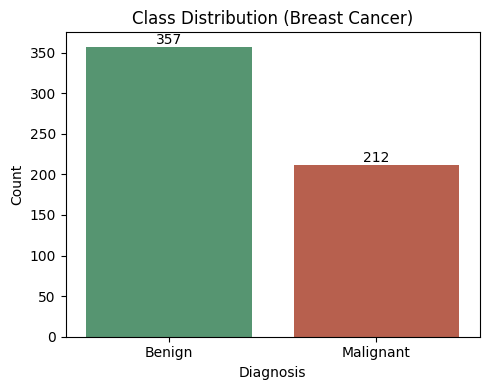

In [69]:
# Class distribution after remapping
### CODE HERE ###
counts = y.value_counts().sort_index()
print(counts.rename({0: 'Benign (0)', 1: 'Malignant (1)'}))
print("\nProportions:\n", y.value_counts(normalize=True).round(3))

plt.figure(figsize=(5, 4))
ax = sns.countplot(x=y.map({0: 'Benign', 1: 'Malignant'}), order=['Benign', 'Malignant'],
                   palette=['#4C9F70', '#C8553D'])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.title('Class Distribution (Breast Cancer)')
plt.xlabel('Diagnosis'); plt.ylabel('Count')
plt.tight_layout(); plt.show()


### 2.4 Feature Distributions <font color="red">[2 marks]</font>

Pick 4-6 features and plot their distributions using histograms or boxplots. Look for skewness, outliers, and whether the two classes separate visually on any feature.


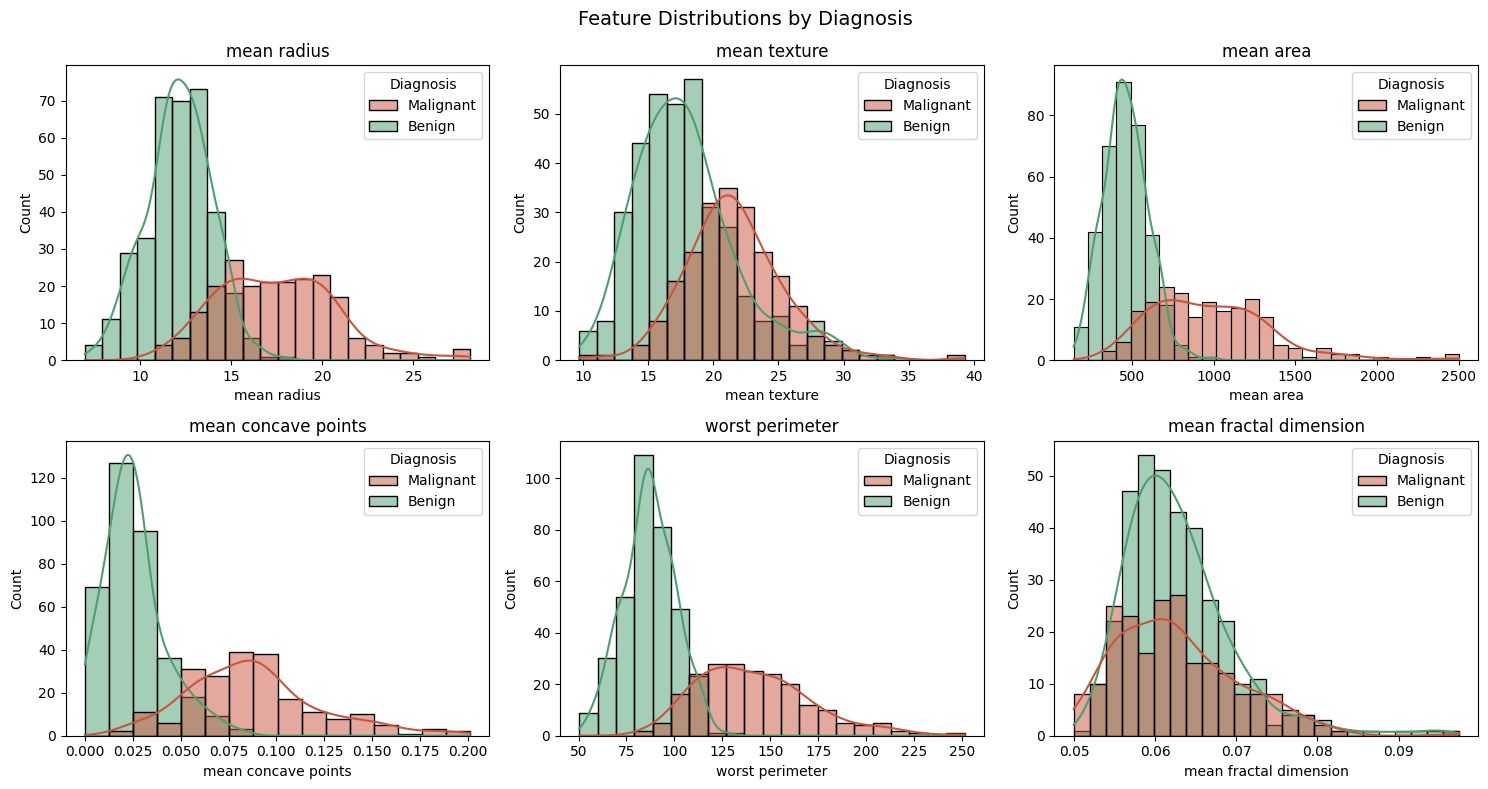

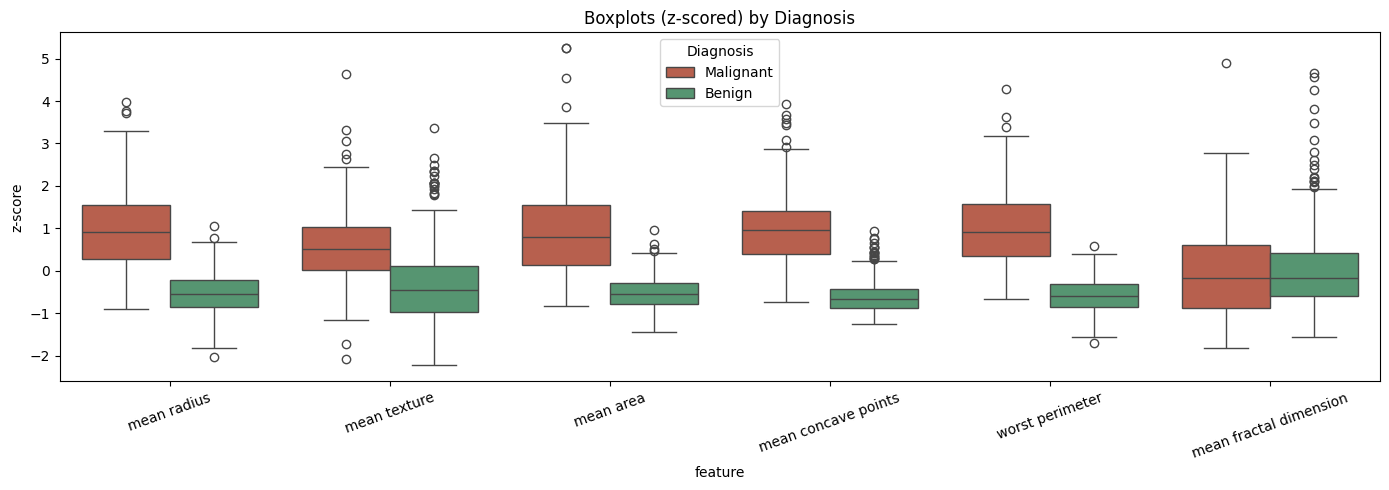

In [70]:
# Feature distributions for 6 selected features, coloured by class
### CODE HERE ###
features = ['mean radius', 'mean texture', 'mean area',
            'mean concave points', 'worst perimeter', 'mean fractal dimension']
plot_df = X[features].copy()
plot_df['Diagnosis'] = y.map({0: 'Benign', 1: 'Malignant'})

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feat in zip(axes.flat, features):
    sns.histplot(data=plot_df, x=feat, hue='Diagnosis', kde=True, ax=ax,
                 palette={'Benign': '#4C9F70', 'Malignant': '#C8553D'}, alpha=0.5)
    ax.set_title(feat)
plt.suptitle('Feature Distributions by Diagnosis', fontsize=14)
plt.tight_layout(); plt.show()

# Boxplots for the same features (standardised so they fit on one axis)
melted = ((X[features] - X[features].mean()) / X[features].std()).assign(
    Diagnosis=plot_df['Diagnosis']).melt(id_vars='Diagnosis', var_name='feature', value_name='z-score')
plt.figure(figsize=(14, 5))
sns.boxplot(data=melted, x='feature', y='z-score', hue='Diagnosis',
            palette={'Benign': '#4C9F70', 'Malignant': '#C8553D'})
plt.xticks(rotation=20); plt.title('Boxplots (z-scored) by Diagnosis')
plt.tight_layout(); plt.show()

### ✍️ Interpretation Checkpoint

**[Your Answer]:** Answer these questions in 2-3 sentences each:
1. Is the dataset balanced? How might imbalance affect model training?
2. Do the features have similar scales? What does this mean for models like KNN and SVM?
3. Why is recall a better primary metric than accuracy for this problem?
4. Why must we fit the scaler on training data only and not on the full dataset? What information from the test set would leak into training if we did?


*Write your answers here:*

1. **Not perfectly balanced:** 357 benign (62.7%) vs 212 malignant (37.3%), roughly 1.7 : 1. An unweighted model can lean toward the majority (benign) class, because that lowers overall error. That shows up as more false negatives, the costly mistake here. I counter it with a **stratified split** (train/test both keep ~37% malignant) and `class_weight='balanced'` (errors on malignant cases cost more during training).

2. **No, the scales are very different.** `mean area` averages ~655 (max 2,501), while `mean smoothness` is ~0.096 and `mean fractal dimension` ~0.063. KNN measures Euclidean distance, and an RBF-SVM's kernel and margin are also distance-based. Unscaled, area and perimeter would dominate every distance and the small-scale features would be effectively ignored. `StandardScaler` puts every feature on mean 0 / std 1 so each one can contribute.

3. **Accuracy hides the error we care about.** A model that calls *every* tumour benign scores 62.7% accuracy and catches **zero** cancers. Recall = TP / (TP + FN) directly measures the share of real cancers we catch. A false negative (cancer sent home) is far worse than a false positive (an extra biopsy), so recall is the primary metric, with precision as a guard-rail (≥ 0.60).

4. **The test set must stand in for future, unseen patients.** If the scaler is fit on all 569 rows, the mean and standard deviation it learns include the test rows. Every training feature is then shifted using information from the test set (its centre and spread). The model is indirectly tuned to the test distribution, and the reported scores become optimistic. You can see the honest version in Stage 3.3: after train-only scaling, the test-set means are *not* exactly 0 (e.g. `mean texture` = −0.115). That small mismatch is exactly what a real deployment would face.


## Stage 3: Data Preprocessing and Preparation

<font color="red">**[7 marks]**</font>


### 3.1 Missing Value Audit <font color="red">[1 mark]</font>

Confirm no missing values exist. If any do, handle them with median imputation.


In [71]:
# Missing value audit
### CODE HERE ###
missing = X.isnull().sum()
print("Columns with missing values:", (missing > 0).sum())
print("Total missing:", missing.sum())
if missing.sum() > 0:
    X = X.fillna(X.median())   # median imputation (not needed here)
    print("Imputed with median.")
else:
    print("No missing values - no imputation needed.")


Columns with missing values: 0
Total missing: 0
No missing values - no imputation needed.


### 3.2 Train-Test Split <font color="red">[2 marks]</font>

Split into 70% training and 30% test using **stratified sampling** to preserve the class ratio to mitigate any slight class imbalance. Use `random_state=42`.


In [72]:
# Stratified train-test split
### CODE HERE ###
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (398, 30) | Test: (171, 30)


### 3.3 Feature Scaling <font color="red">[2 marks]</font>

Apply `StandardScaler`. **Fit the scaler on training data only**, then transform both train and test sets. If you fit on the full dataset, the scaler learns the mean and standard deviation of the test data, which inflates your results. That is data leakage.

> **Note:** Decision Trees split on thresholds and don't need scaling. But for consistency here, we scale for all models.


In [73]:
# Feature scaling: fit on train only, transform both
### CODE HERE ###
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn mean/std from TRAIN only
X_test_scaled = scaler.transform(X_test)         # apply the same mean/std to test
print("Train :", X_train_scaled.mean(axis=0)[:3].round(3))
print("Test :", X_test_scaled.mean(axis=0)[:3].round(3))


Train : [-0. -0.  0.]
Test : [ 0.001 -0.115  0.009]


### 3.4 Confirm Prepared Data <font color="red">[2 marks]</font>

Print shapes of your final training and test sets. Verify the class distribution is preserved in both.


In [74]:
# Confirm prepared data
### CODE HERE ###
print("X_train_scaled:", X_train_scaled.shape, "| y_train:", y_train.shape)
print("X_test_scaled: ", X_test_scaled.shape, "| y_test: ", y_test.shape)
print("\nClass distribution (proportion malignant=1):")
print(pd.DataFrame({'Full': y.value_counts(normalize=True),
                    'Train': y_train.value_counts(normalize=True),
                    'Test': y_test.value_counts(normalize=True)}).round(3))


X_train_scaled: (398, 30) | y_train: (398,)
X_test_scaled:  (171, 30) | y_test:  (171,)

Class distribution (proportion malignant=1):
         Full  Train   Test
target                     
0       0.627  0.628  0.626
1       0.373  0.372  0.374


## Helper: Evaluation Function

You will evaluate many models. Rather than copy-pasting the same five lines every time, define a reusable function. Call it throughout Stages 4-6.


In [75]:
# Helper function. Use this to evaluate all models consistently.
### CODE HERE ###
def evaluate_model(name, y_true, y_pred, average='binary', target_names=None, plot_cm=True):
    """Print key metrics, classification report and confusion matrix; return a metrics dict."""
    if average == 'binary':
        metrics = {
            'Model': name,
            'Accuracy': accuracy_score(y_true, y_pred),
            'Recall': recall_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred),
            'F1': f1_score(y_true, y_pred),
        }
        cm = confusion_matrix(y_true, y_pred)
        metrics['False_Negatives'] = int(cm[1][0])
    else:
        metrics = {
            'Model': name,
            'Accuracy': accuracy_score(y_true, y_pred),
            'Macro_Precision': precision_score(y_true, y_pred, average='macro'),
            'Macro_Recall': recall_score(y_true, y_pred, average='macro'),
            'Macro_F1': f1_score(y_true, y_pred, average='macro'),
        }
        cm = confusion_matrix(y_true, y_pred)

    print(f"===== {name} =====")
    for k, v in metrics.items():
        if k != 'Model':
            print(f"{k:>16}: {v:.4f}" if isinstance(v, float) else f"{k:>16}: {v}")
    print("\n" + classification_report(y_true, y_pred, target_names=target_names, digits=3))

    if plot_cm:
        labels = target_names if target_names is not None else 'auto'
        plt.figure(figsize=(4.5, 3.8))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                    xticklabels=labels, yticklabels=labels)
        plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(f'{name}: Confusion Matrix')
        plt.tight_layout(); plt.show()
    return metrics

BC_LABELS = ['Benign', 'Malignant']
results = {}   # Part 1 test-set metrics, keyed by model name


## How GridSearchCV Works

If you haven't used `GridSearchCV` before, read this before moving on.

`GridSearchCV` automates hyperparameter tuning. You give it a set of parameter values to try, and it trains a model for every combination, scores each one using cross-validation, and tells you which combination won.

You can refer to the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

Here is the pattern you will repeat for every model below:

```python
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

# 1. Define what parameter values to try
param_grid = {'C': [0.1, 1, 10]}

# 2. Set up GridSearchCV
grid = GridSearchCV(
    estimator=LogisticRegression(random_state=42, max_iter=10000),
    param_grid=param_grid,
    scoring='recall',   # what metric to optimise
    cv=5,               # 5-fold cross-validation on training data
    n_jobs=-1            # use all CPU cores
)

# 3. Fit on training data
grid.fit(X_train_scaled, y_train)

# 4. Check results
print("Best parameters:", grid.best_params_)
print("Best CV recall:", grid.best_score_)
best_model = grid.best_estimator_

# 5. Predict on test set
y_pred = best_model.predict(X_test_scaled)
```

Every model below follows the same five steps. The only things that change are the estimator and the parameter grid.


## Stage 4: Model Training, Hyperparameter Tuning, and Evaluation

<font color="red">**[23 marks]**</font>

Train **four classifiers**, tune them, evaluate each one.

For each model:
1. Define the parameter grid
2. Run `GridSearchCV` with `scoring='recall'`, `cv=5`
3. Print the best parameters
4. Predict on the test set using the best estimator
5. Evaluate using `evaluate_model()`

> We use `scoring='recall'` because our goal is to catch malignant cases. Accuracy is misleading when classes are imbalanced.


### 4.1 Logistic Regression (Baseline) <font color="red">[5 marks]</font>

Logistic Regression with `class_weight='balanced'` to handle class imbalance.

**Hyperparameters to tune:**
- `C`: Regularisation strength. Try `[0.01, 0.1, 1, 10, 100]`
- Set `max_iter=10000` and `random_state=42`


In [76]:
# Logistic Regression with GridSearchCV
### CODE HERE ###
lr_grid = GridSearchCV(
    estimator=LogisticRegression(class_weight='balanced', max_iter=10000, random_state=42),
    param_grid={'C': [0.01, 0.1, 1, 10, 100]},
    scoring='recall', cv=5, n_jobs=-1)
lr_grid.fit(X_train_scaled, y_train)
print("Best parameters:", lr_grid.best_params_)
print("Best CV recall: %.4f" % lr_grid.best_score_)
best_lr = lr_grid.best_estimator_


Best parameters: {'C': 10}
Best CV recall: 0.9389


===== Logistic Regression =====
        Accuracy: 0.9708
          Recall: 0.9375
       Precision: 0.9836
              F1: 0.9600
 False_Negatives: 4

              precision    recall  f1-score   support

      Benign      0.964     0.991     0.977       107
   Malignant      0.984     0.938     0.960        64

    accuracy                          0.971       171
   macro avg      0.974     0.964     0.968       171
weighted avg      0.971     0.971     0.971       171



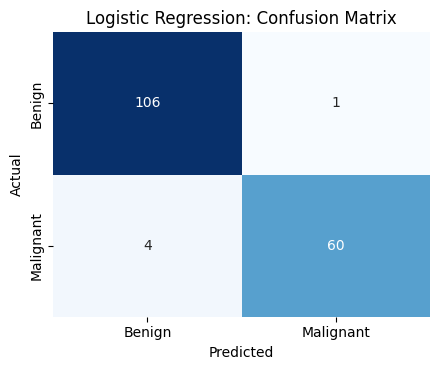

In [77]:
# Evaluate LR on test set
### CODE HERE ###
y_pred_lr = best_lr.predict(X_test_scaled)
results['Logistic Regression'] = evaluate_model('Logistic Regression', y_test, y_pred_lr, target_names=BC_LABELS)


### 4.2 K-Nearest Neighbours (KNN) <font color="red">[6 marks]</font>

[KNN](https://scikit-learn.org/stable/modules/neighbors.html) classifies a sample by majority vote of its nearest neighbours. Sensitive to feature scale, which is why we scaled the data.

**Hyperparameters to tune:**
- `n_neighbors`: Try `[3, 5, 7, 9, 11, 15]`
- `weights`: Try `['uniform', 'distance']`. Uniform gives equal votes. Distance gives closer neighbours more influence.

> Think about it: if malignant samples are sparse in a local neighbourhood, why might `weights='distance'` help?


In [78]:
# KNN with GridSearchCV
### CODE HERE ###
knn_grid = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid={'n_neighbors': [3, 5, 7, 9, 11, 15], 'weights': ['uniform', 'distance']},
    scoring='recall', cv=5, n_jobs=-1)
knn_grid.fit(X_train_scaled, y_train)
print("Best parameters:", knn_grid.best_params_)
print("Best CV recall: %.4f" % knn_grid.best_score_)
best_knn = knn_grid.best_estimator_

Best parameters: {'n_neighbors': 7, 'weights': 'uniform'}
Best CV recall: 0.9253


===== KNN =====
        Accuracy: 0.9649
          Recall: 0.9062
       Precision: 1.0000
              F1: 0.9508
 False_Negatives: 6

              precision    recall  f1-score   support

      Benign      0.947     1.000     0.973       107
   Malignant      1.000     0.906     0.951        64

    accuracy                          0.965       171
   macro avg      0.973     0.953     0.962       171
weighted avg      0.967     0.965     0.965       171



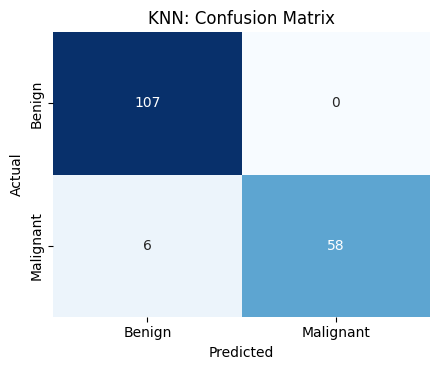

In [79]:
# Evaluate KNN on test set
### CODE HERE ###
y_pred_knn = best_knn.predict(X_test_scaled)
results['KNN'] = evaluate_model('KNN', y_test, y_pred_knn, target_names=BC_LABELS)

### 4.3 Decision Tree <font color="red">[6 marks]</font>

[Decision Trees](https://scikit-learn.org/stable/modules/tree.html) split features at thresholds. Without constraints, they memorise training data perfectly and fail on new data. That is overfitting.

**Hyperparameters to tune:**
- `max_depth`: Try `[3, 5, 7, 10, None]`. `None` means no limit.
- `min_samples_split`: Try `[2, 5, 10]`
- `min_samples_leaf`: Try `[1, 2, 4]`
- Use `class_weight='balanced'` and `random_state=42`


In [80]:
# Decision Tree with GridSearchCV
### CODE HERE ###
dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(class_weight='balanced', random_state=42),
    param_grid={'max_depth': [3, 5, 7, 10, None],
                'min_samples_split': [2, 5, 10],
                'min_samples_leaf': [1, 2, 4]},
    scoring='recall', cv=5, n_jobs=-1)
dt_grid.fit(X_train_scaled, y_train)
print("Best parameters:", dt_grid.best_params_)
print("Best CV recall: %.4f" % dt_grid.best_score_)
best_dt = dt_grid.best_estimator_

Best parameters: {'max_depth': 7, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best CV recall: 0.9320


===== Decision Tree =====
        Accuracy: 0.9064
          Recall: 0.8438
       Precision: 0.9000
              F1: 0.8710
 False_Negatives: 10

              precision    recall  f1-score   support

      Benign      0.910     0.944     0.927       107
   Malignant      0.900     0.844     0.871        64

    accuracy                          0.906       171
   macro avg      0.905     0.894     0.899       171
weighted avg      0.906     0.906     0.906       171



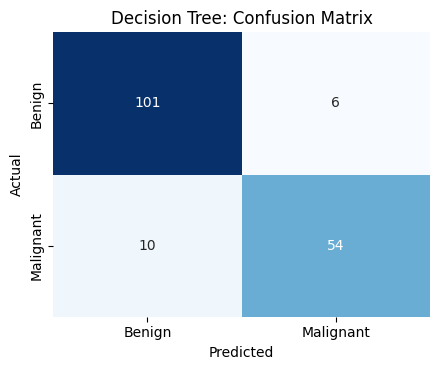

In [81]:
# Evaluate Decision Tree on test set
### CODE HERE ###
y_pred_dt = best_dt.predict(X_test_scaled)
results['Decision Tree'] = evaluate_model('Decision Tree', y_test, y_pred_dt, target_names=BC_LABELS)

### 4.4 Support Vector Machine (SVM) <font color="red">[6 marks]</font>

[SVMs](https://scikit-learn.org/stable/modules/svm.html) find the hyperplane that separates classes with the widest margin. With kernel functions, they can model non-linear boundaries.

**Hyperparameters to tune:**
- `C`: Try `[0.1, 1, 10]`
- `kernel`: Try `['linear', 'rbf']`. Linear for linearly separable data, RBF for non-linear.
- `gamma`: Try `['scale', 'auto']` (matters for RBF kernel)
- Use `class_weight='balanced'`, `random_state=42`, and `probability=True`

> **Why `probability=True`?** We need `predict_proba()` for threshold tuning in Stage 6.


In [82]:
# SVM with GridSearchCV
### CODE HERE ###
svm_grid = GridSearchCV(
    estimator=SVC(class_weight='balanced', probability=True, random_state=42),
    param_grid={'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf'], 'gamma': ['scale', 'auto']},
    scoring='recall', cv=5, n_jobs=-1)
svm_grid.fit(X_train_scaled, y_train)
print("Best parameters:", svm_grid.best_params_)
print("Best CV recall: %.4f" % svm_grid.best_score_)
best_svm = svm_grid.best_estimator_

Best parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV recall: 0.9520


===== SVM =====
        Accuracy: 0.9825
          Recall: 0.9688
       Precision: 0.9841
              F1: 0.9764
 False_Negatives: 2

              precision    recall  f1-score   support

      Benign      0.981     0.991     0.986       107
   Malignant      0.984     0.969     0.976        64

    accuracy                          0.982       171
   macro avg      0.983     0.980     0.981       171
weighted avg      0.982     0.982     0.982       171



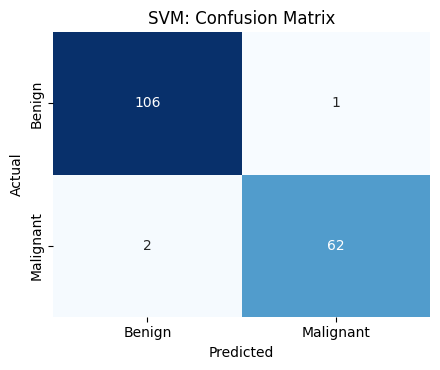

In [83]:
# Evaluate SVM on test set
### CODE HERE ###
y_pred_svm = best_svm.predict(X_test_scaled)
results['SVM'] = evaluate_model('SVM', y_test, y_pred_svm, target_names=BC_LABELS)

## Stage 5: Model Comparison

<font color="red">**[9 marks]**</font>


### 5.1 Build a Comparison Table <font color="red">[3 marks]</font>

Create a DataFrame comparing all four models on the **test set**:
- Accuracy
- Recall (for malignant class)
- Precision (for malignant class)
- F1-Score (for malignant class)
- Number of False Negatives (from confusion matrix)

> **Hint:** A false negative is a malignant case predicted as benign. In the confusion matrix, it sits at position `[1][0]` when malignant = 1.


In [84]:
# Comparison table for all 4 models
### CODE HERE ###
comparison_df = pd.DataFrame(results.values()).set_index('Model')
comparison_df = comparison_df[['Accuracy', 'Recall', 'Precision', 'F1', 'False_Negatives']]
comparison_df.sort_values(['Recall', 'Precision'], ascending=False).round(4)

,Accuracy,Recall,Precision,F1,False_Negatives
Model,,,,,
SVM,0.9825,0.9688,0.9841,0.9764,2
Logistic Regression,0.9708,0.9375,0.9836,0.9600,4
KNN,0.9649,0.9062,1.0000,0.9508,6
Decision Tree,0.9064,0.8438,0.9000,0.8710,10


### 5.2 Visualise Comparison <font color="red">[2 marks]</font>

Create a grouped bar chart comparing Recall and Precision across all four models.


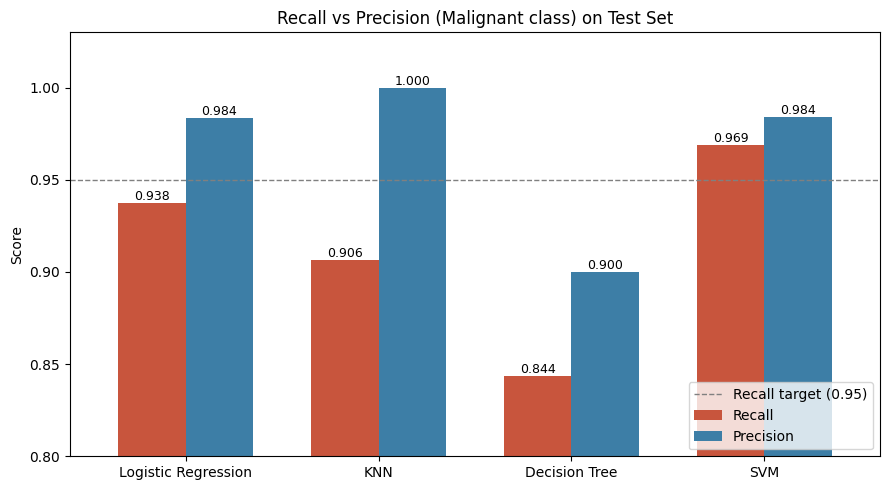

In [85]:
# Grouped bar chart: Recall and Precision
### CODE HERE ###
ax = comparison_df[['Recall', 'Precision']].plot(kind='bar', figsize=(9, 5),
                                                 color=['#C8553D', '#3D7EA6'], width=0.7)
for c in ax.containers:
    ax.bar_label(c, fmt='%.3f', fontsize=9)
ax.axhline(0.95, color='gray', ls='--', lw=1, label='Recall target (0.95)')
ax.set_ylim(0.8, 1.03)
ax.set_title('Recall vs Precision (Malignant class) on Test Set')
ax.set_ylabel('Score'); ax.set_xlabel('')
plt.xticks(rotation=0); plt.legend(loc='lower right')
plt.tight_layout(); plt.show()

### 5.3 Cross-Validation Stability <font color="red">[2 marks]</font>

For **all four models**, run 5-fold stratified [cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html) on the **training set** using `cross_val_score` with `scoring='recall'`. Print the mean and standard deviation of recall for each.

> **Why this matters:** High recall on one split means nothing if the model collapses on another. Stability tells you whether you can trust the number.

> **A caveat:** You are running `cross_val_score` on already-tuned estimators. This is a quick stability check, not a substitute for nested cross-validation. Good enough for a practice exercise.


In [86]:
# Cross-validation stability for all 4 models
### CODE HERE ###
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
best_models = {'Logistic Regression': best_lr, 'KNN': best_knn,
               'Decision Tree': best_dt, 'SVM': best_svm}
cv_rows = []
for name, model in best_models.items():
    scores = cross_val_score(model, X_train_scaled, y_train, cv=skf, scoring='recall', n_jobs=-1)
    cv_rows.append({'Model': name, 'CV_Recall_Mean': scores.mean(), 'CV_Recall_Std': scores.std()})
    print(f"{name:<20} recall = {scores.mean():.4f} +/- {scores.std():.4f}   folds: {np.round(scores, 3)}")
cv_df = pd.DataFrame(cv_rows).set_index('Model')

Logistic Regression  recall = 0.9524 +/- 0.0175   folds: [0.967 0.967 0.967 0.931 0.931]
KNN                  recall = 0.9251 +/- 0.0511   folds: [0.933 0.967 0.967 0.828 0.931]
Decision Tree        recall = 0.8782 +/- 0.0724   folds: [0.933 0.767 0.967 0.828 0.897]
SVM                  recall = 0.9524 +/- 0.0279   folds: [0.967 0.967 0.967 0.897 0.966]


### 5.4 Feature Importance <font color="red">[2 marks]</font>

Knowing *which features drive predictions* matters as much as the predictions themselves.

- Extract **feature importances** from your best Decision Tree (`.feature_importances_`) or **coefficients** from Logistic Regression (`.coef_[0]`)
- Plot the **top 10 most important features** as a horizontal bar chart


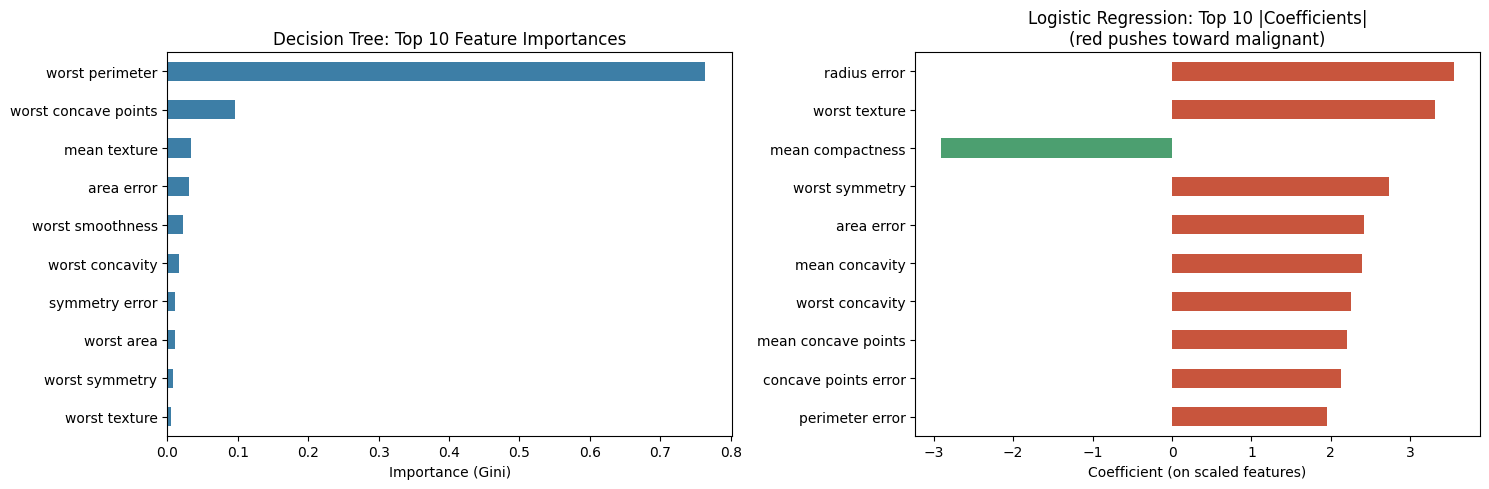

Top 5 DT features:
 worst perimeter         0.763
worst concave points    0.096
mean texture            0.034
area error              0.031
worst smoothness        0.022
dtype: float64


In [87]:
# Feature importance from Decision Tree
### CODE HERE ###
dt_imp = pd.Series(best_dt.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
lr_coef = pd.Series(best_lr.coef_[0], index=X.columns)
lr_top = lr_coef.reindex(lr_coef.abs().sort_values(ascending=False).index).head(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
dt_imp[::-1].plot(kind='barh', ax=axes[0], color='#3D7EA6')
axes[0].set_title('Decision Tree: Top 10 Feature Importances'); axes[0].set_xlabel('Importance (Gini)')
lr_top[::-1].plot(kind='barh', ax=axes[1], color=['#C8553D' if v > 0 else '#4C9F70' for v in lr_top[::-1]])
axes[1].set_title('Logistic Regression: Top 10 |Coefficients|\n(red pushes toward malignant)')
axes[1].set_xlabel('Coefficient (on scaled features)')
plt.tight_layout(); plt.show()
print("Top 5 DT features:\n", dt_imp.head(5).round(3))


## Stage 6: Final Model Selection

<font color="red">**[5 marks]**</font>


### 6.1 Threshold Tuning <font color="red">[2 marks]</font>

By default, classifiers use a probability threshold of 0.5 to assign classes. For medical diagnosis, we can lower this threshold to catch more malignant cases (higher recall) at the cost of more false positives (lower precision).

**Steps:**
1. Create a **stratified validation split from your training data** (70/30 from `X_train_scaled`). Do not touch the test set for this.
2. Retrain your best model on the inner training portion
3. Get predicted probabilities on the validation portion using `predict_proba()`
4. Plot the **precision-recall curve**
5. Find a threshold where recall ≥ 0.95

> **Why not tune on the test set?** If you use the test set to pick a threshold, your final evaluation on that same test set is no longer honest. The test set becomes a tuning surface, and your reported metrics are optimistic.


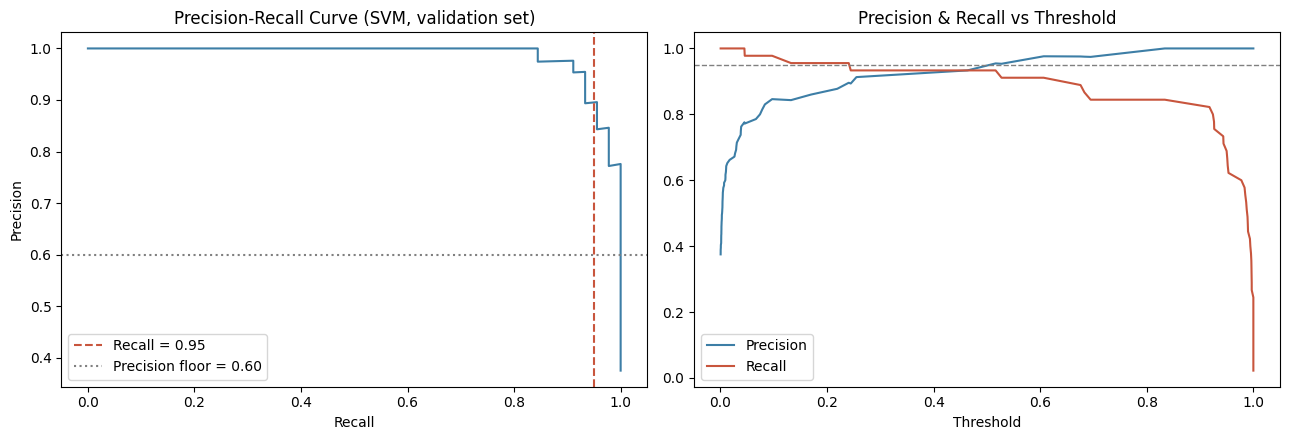

Chosen threshold: 0.2408
Validation recall = 0.9556, precision = 0.8958

Test @ threshold 0.241: recall = 0.9844, precision = 0.9692, FN = 1, FP = 2


In [88]:
# Threshold tuning on a VALIDATION split (not test set)
from sklearn.base import clone

# Step 1: Create inner split from training data
X_tr_in, X_val, y_tr_in, y_val = train_test_split(
    X_train_scaled, y_train, test_size=0.3, stratify=y_train, random_state=42)

# Step 2: Retrain best model (SVM) on inner training set
svm_val = clone(best_svm).fit(X_tr_in, y_tr_in)

# Step 3: Get predicted probabilities on validation set
val_proba = svm_val.predict_proba(X_val)[:, 1]

# Step 4: Plot precision-recall curve
precisions, recalls, thresholds = precision_recall_curve(y_val, val_proba)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(recalls, precisions, color='#3D7EA6')
axes[0].axvline(0.95, color='#C8553D', ls='--', label='Recall = 0.95')
axes[0].axhline(0.60, color='gray', ls=':', label='Precision floor = 0.60')
axes[0].set_xlabel('Recall'); axes[0].set_ylabel('Precision')
axes[0].set_title('Precision-Recall Curve (SVM, validation set)'); axes[0].legend()
axes[1].plot(thresholds, precisions[:-1], label='Precision', color='#3D7EA6')
axes[1].plot(thresholds, recalls[:-1], label='Recall', color='#C8553D')
axes[1].axhline(0.95, color='gray', ls='--', lw=1)
axes[1].set_xlabel('Threshold'); axes[1].set_title('Precision & Recall vs Threshold'); axes[1].legend()
plt.tight_layout(); plt.show()

# Step 5: Find threshold where recall >= 0.95
# Among thresholds meeting recall >= 0.95, pick the HIGHEST one (best precision while still meeting recall)
ok = np.where(recalls[:-1] >= 0.95)[0]
best_idx = ok[np.argmax(thresholds[ok])]
chosen_threshold = thresholds[best_idx]
print(f"Chosen threshold: {chosen_threshold:.4f}")
print(f"Validation recall = {recalls[best_idx]:.4f}, precision = {precisions[best_idx]:.4f}")

# Apply the chosen threshold ONCE to the test set (using the full-train SVM) as the final honest check
test_proba = best_svm.predict_proba(X_test_scaled)[:, 1]
y_pred_thr = (test_proba >= chosen_threshold).astype(int)
cm_thr = confusion_matrix(y_test, y_pred_thr)
print(f"\nTest @ threshold {chosen_threshold:.3f}: recall = {recall_score(y_test, y_pred_thr):.4f}, "
      f"precision = {precision_score(y_test, y_pred_thr):.4f}, FN = {cm_thr[1][0]}, FP = {cm_thr[0][1]}")


### 6.2 Final Recommendation <font color="red">[3 marks]</font>

**[Your Answer]:** Answer the following. Cite specific numbers from your results.

1. Which model do you recommend and why? Reference its recall, false negative count, and cross-validation stability.
2. How many false negatives does it produce on the test set? Is this clinically acceptable?
3. What is one specific limitation of your analysis? (Not "more data." Be concrete, e.g., "the dataset has only 569 samples, which limits the reliability of cross-validation estimates.")


*Write your answers here:*

1. **SVM (RBF kernel, C=1, gamma='scale').** It has the highest test recall (**0.969**), the fewest false negatives (**2**), precision **0.984**, F1 **0.976** and accuracy **0.982**. It is also the only model that clears the 0.95 recall target at the default threshold. Its 5-fold CV recall is **0.952 ± 0.028**, tied for the highest mean with Logistic Regression (0.952 ± 0.018). LR is slightly more stable across folds but misses 4 cancers on test, versus 2 for SVM. Decision Tree is clearly worst (CV 0.878 ± 0.072, 10 FN), so a single tree is too unstable for this task. SVM also gives probabilities, which let us tune the decision threshold.

2. **2 false negatives** out of 64 malignant test cases at the default 0.5 threshold. That meets the stated constraint (recall 0.969 ≥ 0.95, precision 0.984 ≥ 0.60). After tuning the threshold on the validation split (threshold ≈ **0.24**) and applying it once to the test set, FN falls to **1** while FP is only **2** (recall 0.984, precision 0.969). Clinically, even one missed cancer is serious. So this is acceptable only as a **screening/triage aid** with a radiologist or pathologist reviewing cases, not as a standalone diagnosis.

3. **Small number of positive test cases.** The test set has only **64 malignant cases**, so each missed cancer moves recall by 1.6 points (1/64). The "SVM beats LR" result is really a difference of just **2 patients**, which is within noise. Similarly, the 0.24 threshold was chosen on a validation split of only 120 samples (~45 malignant), so the threshold itself is uncertain. A repeated or nested CV would give a confidence interval instead of a single number.

---
# PART 2: Multiclass Classification, Wine Dataset

## Context

The Wine dataset contains chemical analysis results of wines from the same region of Italy, grown from **three different cultivars** (grape varieties). The task: predict the cultivar (class 0, 1, or 2) based on 13 chemical attributes like alcohol content, malic acid, and flavanoids.

**Why Macro-F1 matters here:** No single wine class is more "dangerous" to misclassify. All three matter equally. Macro-averaged F1-score treats each class the same regardless of size.


## Stage 1: Data and Package Loading

<font color="red">**[2 marks]**</font>

Load the Wine dataset from `sklearn.datasets`. Convert to a DataFrame. Separate features and target. Import `MLPClassifier`.


In [89]:
# Pre-imported for Part 2
from sklearn.neural_network import MLPClassifier
from sklearn.datasets import load_wine

# Load wine dataset
wine_data = load_wine()
wine_df = pd.DataFrame(wine_data.data, columns=wine_data.feature_names)
wine_df['target'] = wine_data.target
X_w = wine_df.drop(columns='target')
y_w = wine_df['target']
WINE_LABELS = [str(n) for n in wine_data.target_names]
print("X_w:", X_w.shape, "| y_w:", y_w.shape, "| classes:", WINE_LABELS)

X_w: (178, 13) | y_w: (178,) | classes: ['class_0', 'class_1', 'class_2']


## Stage 2: Data Understanding

<font color="red">**[6 marks]**</font>


### 2.1 Basic Inspection <font color="red">[2 marks]</font>

Display the shape, first few rows, data types, and check for missing values.


In [90]:
# Inspect the wine dataset
print("Shape:", wine_df.shape)
print("\nData types:\n", wine_df.dtypes.value_counts())
print("\nTotal missing values:", wine_df.isnull().sum().sum())
wine_df.head()


Shape: (178, 14)

Data types:
 float64    13
int64       1
Name: count, dtype: int64

Total missing values: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


### 2.2 Class Distribution <font color="red">[2 marks]</font>

How many wines in each class? Visualise with a bar plot.


target
0    59
1    71
2    48
Name: count, dtype: int64

Proportions:
 target
0    0.331
1    0.399
2    0.270
Name: proportion, dtype: float64


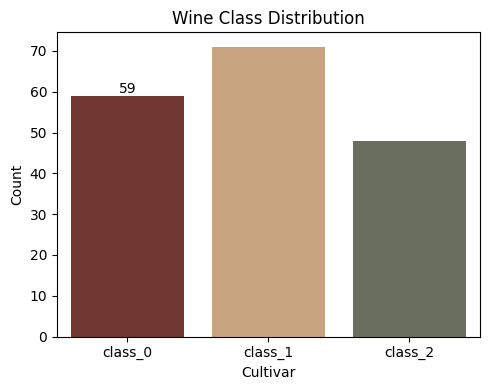

In [91]:
# Wine class distribution
w_counts = y_w.value_counts().sort_index()
print(w_counts)
print("\nProportions:\n", y_w.value_counts(normalize=True).sort_index().round(3))

plt.figure(figsize=(5, 4))
ax = sns.countplot(x=y_w, palette=['#7B2D26', '#D4A373', '#6B705C'])
ax.bar_label(ax.containers[0])
ax.set_xticklabels(WINE_LABELS)
plt.title('Wine Class Distribution'); plt.xlabel('Cultivar'); plt.ylabel('Count')
plt.tight_layout(); plt.show()


### 2.3 Feature Analysis <font color="red">[2 marks]</font>

Look at the feature ranges using `.describe()`. Some features range in the hundreds, others below 1. Then plot a **correlation heatmap** to see which features move together.


,mean,std,min,max
alcohol,13.001,0.812,11.03,14.83
malic_acid,2.336,1.117,0.74,5.80
ash,2.367,0.274,1.36,3.23
alcalinity_of_ash,19.495,3.340,10.60,30.00
magnesium,99.742,14.282,70.00,162.00
total_phenols,2.295,0.626,0.98,3.88
flavanoids,2.029,0.999,0.34,5.08
nonflavanoid_phenols,0.362,0.124,0.13,0.66
proanthocyanins,1.591,0.572,0.41,3.58
color_intensity,5.058,2.318,1.28,13.00


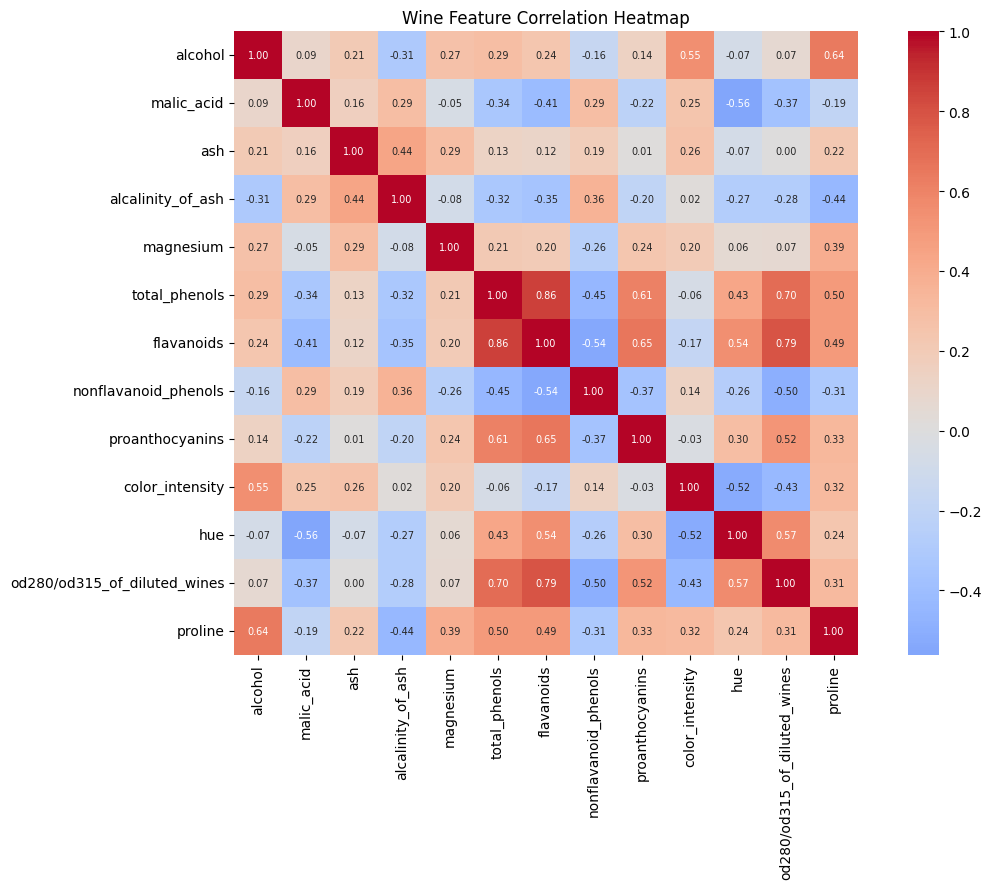

In [92]:
# Summary statistics
display(X_w.describe().T[['mean', 'std', 'min', 'max']].round(3))

# Correlation heatmap
plt.figure(figsize=(12, 9))
sns.heatmap(X_w.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0,
            annot_kws={'size': 7}, square=True)
plt.title('Wine Feature Correlation Heatmap')
plt.tight_layout(); plt.show()


### ✍️ Interpretation Checkpoint

**[Your Answer]:**
1. Are the three wine classes roughly balanced?
2. Looking at the feature ranges, do some features dominate others in scale? What does this imply for models like KNN and SVM?


*Write your answers here:*

1. **Roughly balanced, mildly uneven:** class_0 = 59 (33.1%), class_1 = 71 (39.9%), class_2 = 48 (27.0%). The largest class is ~1.5× the smallest. That isn't severe, but it's why we use a stratified split and judge models on **macro-F1**, which weights all three cultivars equally.

2. **Yes.** `proline` averages ~747 (range 278–1,680) and `magnesium` ~100, while `hue` is ~0.96 and `nonflavanoid_phenols` ~0.36. Unscaled, proline alone would dominate KNN's Euclidean distances and the RBF-SVM kernel, and it would slow gradient-based training for LR and the MLP. So scaling is essential. The heatmap also shows strongly related features: `flavanoids` and `total_phenols` (r = 0.86) and `flavanoids` and `od280/od315` (r = 0.79). These carry overlapping information, which regularisation (C / alpha) helps manage.

## Stage 3: Data Preprocessing

<font color="red">**[4 marks]**</font>


### 3.1 Split and Scale <font color="red">[2 marks]</font>

Stratified train-test split (70-30, `random_state=42`), then `StandardScaler` fit on training data only. Stratification for handling any slight class imbalance in the data.

> **Reminder:** Decision Trees don't need scaling, but KNN, SVM, MLP, and Logistic Regression all do. We scale for all models here.


In [93]:
# Stratified train-test split
Xw_train, Xw_test, yw_train, yw_test = train_test_split(
    X_w, y_w, test_size=0.3, stratify=y_w, random_state=42)

In [94]:
# Scale features: fit on train, transform both
w_scaler = StandardScaler()
Xw_train_scaled = w_scaler.fit_transform(Xw_train)
Xw_test_scaled = w_scaler.transform(Xw_test)

### 3.2 Verify Preparation <font color="red">[2 marks]</font>

Print shapes and class distributions for both splits.


In [95]:
# Verify preparation
print("Xw_train_scaled:", Xw_train_scaled.shape, "| yw_train:", yw_train.shape)
print("Xw_test_scaled: ", Xw_test_scaled.shape, "| yw_test: ", yw_test.shape)
print("\nClass counts:")
print(pd.DataFrame({'Train': yw_train.value_counts().sort_index(),
                    'Test': yw_test.value_counts().sort_index()}))
print("\nClass proportions:")
print(pd.DataFrame({'Full': y_w.value_counts(normalize=True).sort_index(),
                    'Train': yw_train.value_counts(normalize=True).sort_index(),
                    'Test': yw_test.value_counts(normalize=True).sort_index()}).round(3))

Xw_train_scaled: (124, 13) | yw_train: (124,)
Xw_test_scaled:  (54, 13) | yw_test:  (54,)

Class counts:
        Train  Test
target             
0          41    18
1          50    21
2          33    15

Class proportions:
         Full  Train   Test
target                     
0       0.331  0.331  0.333
1       0.399  0.403  0.389
2       0.270  0.266  0.278


## Stage 4: Model Training and Hyperparameter Tuning

<font color="red">**[20 marks]**</font>

Train **five classifiers** on the wine dataset. Use `GridSearchCV` with `scoring='f1_macro'` and `cv=5` for each. Use the `evaluate_model()` helper from Part 1.

> **Key difference from Part 1:** We optimise for `f1_macro` instead of `recall`, because all classes matter equally.


### 4.1 Logistic Regression <font color="red">[3 marks]</font>

**Hyperparameters:**
- `C`: `[0.01, 0.1, 1, 10]`
- `max_iter`: `10000`
- `random_state`: `42`


Best parameters: {'C': 0.1} | Best CV macro-F1: 0.9834
===== Logistic Regression (Wine) =====
        Accuracy: 1.0000
 Macro_Precision: 1.0000
    Macro_Recall: 1.0000
        Macro_F1: 1.0000

              precision    recall  f1-score   support

     class_0      1.000     1.000     1.000        18
     class_1      1.000     1.000     1.000        21
     class_2      1.000     1.000     1.000        15

    accuracy                          1.000        54
   macro avg      1.000     1.000     1.000        54
weighted avg      1.000     1.000     1.000        54



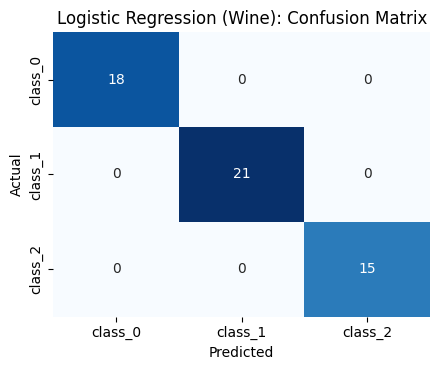

In [96]:
# Logistic Regression for Wine
w_results = {}
w_lr_grid = GridSearchCV(LogisticRegression(max_iter=10000, random_state=42),
                         {'C': [0.01, 0.1, 1, 10]}, scoring='f1_macro', cv=5, n_jobs=-1)
w_lr_grid.fit(Xw_train_scaled, yw_train)
print("Best parameters:", w_lr_grid.best_params_, "| Best CV macro-F1: %.4f" % w_lr_grid.best_score_)
w_best_lr = w_lr_grid.best_estimator_
w_results['Logistic Regression'] = evaluate_model('Logistic Regression (Wine)', yw_test,
    w_best_lr.predict(Xw_test_scaled), average='macro', target_names=WINE_LABELS)

### 4.2 K-Nearest Neighbours <font color="red">[3 marks]</font>

**Hyperparameters:**
- `n_neighbors`: `[3, 5, 7, 9, 11]`
- `weights`: `['uniform', 'distance']`


Best parameters: {'n_neighbors': 11, 'weights': 'uniform'} | Best CV macro-F1: 0.9776
===== KNN (Wine) =====
        Accuracy: 0.9630
 Macro_Precision: 0.9608
    Macro_Recall: 0.9683
        Macro_F1: 0.9625

              precision    recall  f1-score   support

     class_0      1.000     1.000     1.000        18
     class_1      1.000     0.905     0.950        21
     class_2      0.882     1.000     0.938        15

    accuracy                          0.963        54
   macro avg      0.961     0.968     0.963        54
weighted avg      0.967     0.963     0.963        54



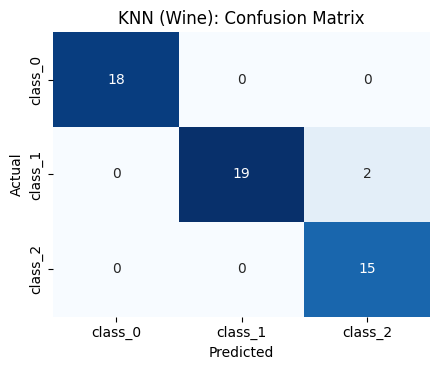

In [97]:
# KNN for Wine
w_knn_grid = GridSearchCV(KNeighborsClassifier(),
                          {'n_neighbors': [3, 5, 7, 9, 11], 'weights': ['uniform', 'distance']},
                          scoring='f1_macro', cv=5, n_jobs=-1)
w_knn_grid.fit(Xw_train_scaled, yw_train)
print("Best parameters:", w_knn_grid.best_params_, "| Best CV macro-F1: %.4f" % w_knn_grid.best_score_)
w_best_knn = w_knn_grid.best_estimator_
w_results['KNN'] = evaluate_model('KNN (Wine)', yw_test,
    w_best_knn.predict(Xw_test_scaled), average='macro', target_names=WINE_LABELS)

### 4.3 Decision Tree <font color="red">[3 marks]</font>

**Hyperparameters:**
- `max_depth`: `[3, 5, 7, 10, None]`
- `min_samples_split`: `[2, 5, 10]`
- `min_samples_leaf`: `[1, 2, 4]`
- `random_state`: `42`


Best parameters: {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 5} | Best CV macro-F1: 0.8800
===== Decision Tree (Wine) =====
        Accuracy: 0.9630
 Macro_Precision: 0.9710
    Macro_Recall: 0.9593
        Macro_F1: 0.9638

              precision    recall  f1-score   support

     class_0      1.000     0.944     0.971        18
     class_1      0.913     1.000     0.955        21
     class_2      1.000     0.933     0.966        15

    accuracy                          0.963        54
   macro avg      0.971     0.959     0.964        54
weighted avg      0.966     0.963     0.963        54



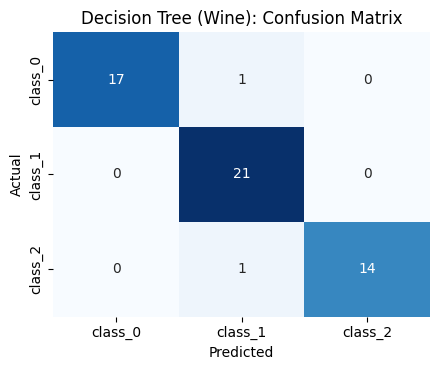

In [98]:
# Decision Tree for Wine
w_dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=42),
                         {'max_depth': [3, 5, 7, 10, None],
                          'min_samples_split': [2, 5, 10],
                          'min_samples_leaf': [1, 2, 4]},
                         scoring='f1_macro', cv=5, n_jobs=-1)
w_dt_grid.fit(Xw_train_scaled, yw_train)
print("Best parameters:", w_dt_grid.best_params_, "| Best CV macro-F1: %.4f" % w_dt_grid.best_score_)
w_best_dt = w_dt_grid.best_estimator_
w_results['Decision Tree'] = evaluate_model('Decision Tree (Wine)', yw_test,
    w_best_dt.predict(Xw_test_scaled), average='macro', target_names=WINE_LABELS)

### 4.4 Support Vector Machine <font color="red">[3 marks]</font>

**Hyperparameters:**
- `C`: `[0.1, 1, 10]`
- `kernel`: `['linear', 'rbf']`
- `gamma`: `['scale', 'auto']`
- `random_state`: `42`


Best parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'} | Best CV macro-F1: 0.9920
===== SVM (Wine) =====
        Accuracy: 0.9815
 Macro_Precision: 0.9848
    Macro_Recall: 0.9778
        Macro_F1: 0.9808

              precision    recall  f1-score   support

     class_0      1.000     1.000     1.000        18
     class_1      0.955     1.000     0.977        21
     class_2      1.000     0.933     0.966        15

    accuracy                          0.981        54
   macro avg      0.985     0.978     0.981        54
weighted avg      0.982     0.981     0.981        54



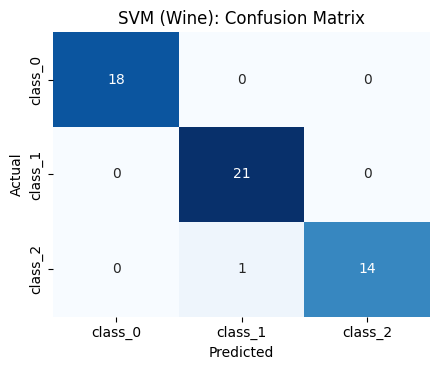

In [99]:
# SVM for Wine
w_svm_grid = GridSearchCV(SVC(random_state=42),
                          {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf'], 'gamma': ['scale', 'auto']},
                          scoring='f1_macro', cv=5, n_jobs=-1)
w_svm_grid.fit(Xw_train_scaled, yw_train)
print("Best parameters:", w_svm_grid.best_params_, "| Best CV macro-F1: %.4f" % w_svm_grid.best_score_)
w_best_svm = w_svm_grid.best_estimator_
w_results['SVM'] = evaluate_model('SVM (Wine)', yw_test,
    w_best_svm.predict(Xw_test_scaled), average='macro', target_names=WINE_LABELS)

### 4.5 Multi-Layer Perceptron (MLP) <font color="red">[8 marks]</font>

The MLP is a neural network. Unlike the previous models, you control the **architecture**: how many layers, how many neurons per layer.

**Hyperparameters to tune:**
- `hidden_layer_sizes`: Try `[(50,), (100,), (50, 50), (100, 50)]`. Each tuple defines layer widths.
- `activation`: Try `['relu', 'tanh']`. The non-linear function at each neuron.
- `alpha`: Try `[0.0001, 0.001, 0.01]`. L2 regularisation to prevent overfitting.
- Set `max_iter=2000`, `random_state=42`, and `early_stopping=True`

> **What is early stopping?** It monitors validation performance during training and stops when performance plateaus. Without it, the network keeps training until it memorises the data.


In [100]:
# MLP for Wine
mlp_grid = GridSearchCV(
    MLPClassifier(max_iter=2000, random_state=42, early_stopping=True),
    {'hidden_layer_sizes': [(50,), (100,), (50, 50), (100, 50)],
     'activation': ['relu', 'tanh'],
     'alpha': [0.0001, 0.001, 0.01]},
    scoring='f1_macro', cv=5, n_jobs=-1)
mlp_grid.fit(Xw_train_scaled, yw_train)
print("Best parameters:", mlp_grid.best_params_)
print("Best CV macro-F1: %.4f" % mlp_grid.best_score_)
w_best_mlp = mlp_grid.best_estimator_

# How did each architecture do? (best CV score per hidden_layer_sizes)
mlp_cv = pd.DataFrame(mlp_grid.cv_results_)
mlp_cv['arch'] = mlp_cv['param_hidden_layer_sizes'].astype(str)
print("\nBest CV macro-F1 by architecture / activation:")
print(mlp_cv.pivot_table(index='arch', columns='param_activation',
                         values='mean_test_score', aggfunc='max').round(4))

Best parameters: {'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': (100,)}
Best CV macro-F1: 0.9136

Best CV macro-F1 by architecture / activation:
param_activation    relu    tanh
arch                            
(100, 50)         0.6704  0.9048
(100,)            0.8891  0.9136
(50, 50)          0.7364  0.8255
(50,)             0.6426  0.6155


===== MLP (Wine) =====
        Accuracy: 0.8519
 Macro_Precision: 0.8720
    Macro_Recall: 0.8730
        Macro_F1: 0.8506

              precision    recall  f1-score   support

     class_0      0.783     1.000     0.878        18
     class_1      1.000     0.619     0.765        21
     class_2      0.833     1.000     0.909        15

    accuracy                          0.852        54
   macro avg      0.872     0.873     0.851        54
weighted avg      0.881     0.852     0.843        54



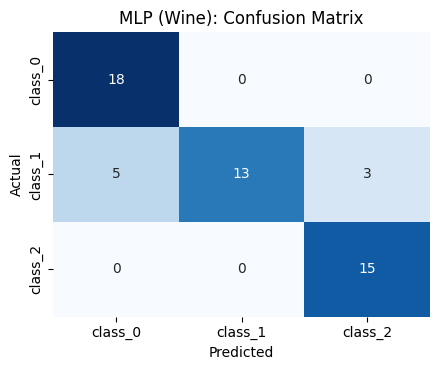

In [101]:
# Evaluate MLP on test set
w_results['MLP'] = evaluate_model('MLP (Wine)', yw_test,
    w_best_mlp.predict(Xw_test_scaled), average='macro', target_names=WINE_LABELS)

### ✍️ MLP Interpretation

**[Your Answer]:**
1. What architecture (hidden layer sizes) performed best? Why do you think that configuration won?
2. Did the MLP outperform the classical models? By how much in macro-F1?
3. What role does `alpha` (regularisation) play? What happens if it is set too high? Too low?


*Write your answers here:*

1. **Best: one hidden layer of 100 neurons, `tanh`, `alpha=0.0001`** (CV macro-F1 0.914). With only 124 training wines and 13 features, and with classes that are close to linearly separable (LR reaches 1.000 on test), a single wide layer has enough capacity. Deeper nets like (100, 50) and (50, 50) add many weights without adding useful signal. `tanh` beat `relu` for every architecture. Training here was cut very short (see Q2), and the smooth, zero-centred `tanh` converges faster in those few iterations.

2. **No, the MLP clearly underperformed.** Its test macro-F1 is **0.851**, versus **1.000** for Logistic Regression (−0.149) and **0.981** for SVM (−0.130). Its CV score is also the most unstable (0.851 ± 0.097). The diagnostic cell below explains why. `early_stopping=True` holds out 10% of the training data (12 rows, 10 inside each CV fold) as a validation set. A validation score on 10 rows is very noisy, so training stops after only **~28 iterations**, before the network has learned the pattern. The same network with early stopping turned off reaches **0.983**. The lesson: on tiny datasets, early stopping can cause *underfitting* instead of preventing overfitting.

3. **`alpha` is an L2 penalty** (it adds alpha × sum of squared weights to the loss), which pushes weights toward small values and keeps the decision boundary smooth. **Too high:** weights are crushed toward zero, so the network can't represent even the real pattern and it *underfits* (boundaries become nearly linear or flat). **Too low (≈0):** nothing stops the weights from growing to fit noise in individual samples, so it *overfits*, especially with many neurons and few rows. Here the grid chose the smallest value (0.0001), because early stopping was already restricting the model so heavily.

## Stage 5: Model Comparison

<font color="red">**[8 marks]**</font>


### 5.1 Comparison Table <font color="red">[3 marks]</font>

Create a DataFrame comparing all five models on the **test set**:
- Accuracy
- Macro-Precision
- Macro-Recall
- Macro-F1-Score


In [102]:
# Comparison table for all 5 wine models
w_comparison_df = pd.DataFrame(w_results.values())
w_comparison_df['Model'] = list(w_results.keys())
w_comparison_df = w_comparison_df.set_index('Model')[['Accuracy', 'Macro_Precision', 'Macro_Recall', 'Macro_F1']]
w_comparison_df.sort_values('Macro_F1', ascending=False).round(4)

,Accuracy,Macro_Precision,Macro_Recall,Macro_F1
Model,,,,
Logistic Regression,1.0000,1.0000,1.0000,1.0000
SVM,0.9815,0.9848,0.9778,0.9808
Decision Tree,0.9630,0.9710,0.9593,0.9638
KNN,0.9630,0.9608,0.9683,0.9625
MLP,0.8519,0.8720,0.8730,0.8506


### 5.2 Visualise Comparison <font color="red">[2 marks]</font>

Bar chart comparing Macro-F1 scores across all five models.


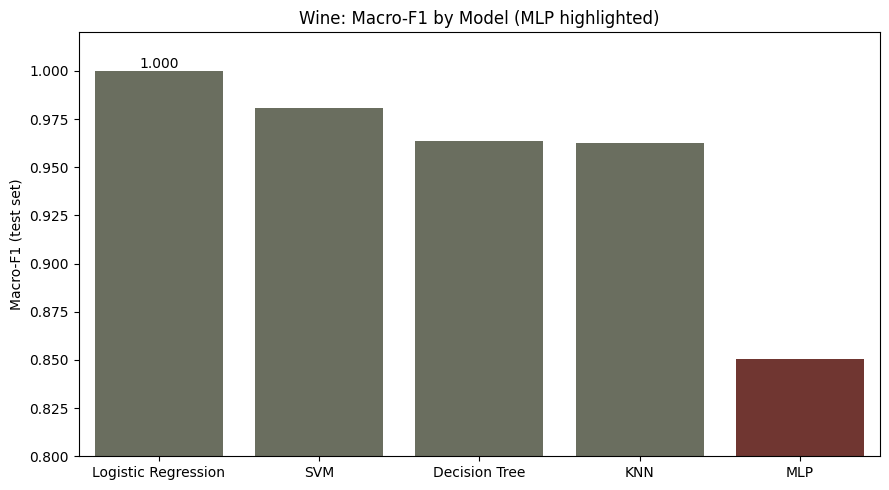

In [103]:
# Macro-F1 bar chart
order = w_comparison_df['Macro_F1'].sort_values(ascending=False)
plt.figure(figsize=(9, 5))
ax = sns.barplot(x=order.index, y=order.values,
                 palette=['#7B2D26' if m == 'MLP' else '#6B705C' for m in order.index])
ax.bar_label(ax.containers[0], fmt='%.3f')
plt.ylim(0.8, 1.02); plt.ylabel('Macro-F1 (test set)'); plt.xlabel('')
plt.title('Wine: Macro-F1 by Model (MLP highlighted)')
plt.tight_layout(); plt.show()

### 5.3 Cross-Validation Stability <font color="red">[3 marks]</font>

For **all five models**, run 5-fold cross-validation with `scoring='f1_macro'` on the training set. Print the mean and standard deviation for each.


In [104]:
# Cross-validation stability for all 5 wine models
w_skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
w_models = {'Logistic Regression': w_best_lr, 'KNN': w_best_knn, 'Decision Tree': w_best_dt,
            'SVM': w_best_svm, 'MLP': w_best_mlp}
w_cv_rows = []
for name, model in w_models.items():
    s = cross_val_score(model, Xw_train_scaled, yw_train, cv=w_skf, scoring='f1_macro', n_jobs=-1)
    w_cv_rows.append({'Model': name, 'CV_F1_Mean': s.mean(), 'CV_F1_Std': s.std()})
    print(f"{name:<20} macro-F1 = {s.mean():.4f} +/- {s.std():.4f}   folds: {np.round(s, 3)}")
w_cv_df = pd.DataFrame(w_cv_rows).set_index('Model')

Logistic Regression  macro-F1 = 0.9760 +/- 0.0321   folds: [0.92 1.   1.   0.96 1.  ]
KNN                  macro-F1 = 0.9628 +/- 0.0334   folds: [0.93  1.    0.963 0.921 1.   ]
Decision Tree        macro-F1 = 0.8931 +/- 0.0435   folds: [0.921 0.879 0.963 0.844 0.859]
SVM                  macro-F1 = 0.9920 +/- 0.0159   folds: [1.   1.   1.   0.96 1.  ]
MLP                  macro-F1 = 0.8508 +/- 0.0969   folds: [0.761 0.838 0.732 0.96  0.963]


### ✍️ Classical vs Neural Comparison

**[Your Answer]:**
1. Which classical model performed best on macro-F1? Why might that be?
2. Did the MLP beat the classical models by a clear margin, or was the gap small?
3. When would you choose a simpler model like Logistic Regression over the MLP, even if the MLP scores slightly higher?


*Write your answers here:*

1. **Logistic Regression had the best test macro-F1 (1.000)**, and **SVM (RBF) had the best and most stable CV macro-F1 (0.992 ± 0.016)**, with 0.981 on test. Both work well because the three cultivars are well separated by a few chemical axes (flavanoids, proline, colour intensity, od280). In 13-D chemistry space, a linear or smooth kernel boundary is enough. Margin-based models also cope well with small, clean tabular data. The Decision Tree was the weakest classical model on CV (0.893 ± 0.044): axis-aligned splits learned from ~124 rows vary a lot from fold to fold.

2. **The gap went the wrong way, and by a clear margin.** The MLP scored 0.851, roughly 0.13–0.15 *below* the classical models, with the widest CV spread (±0.097). Once the early-stopping problem is removed it reaches ~0.98, which only *ties* SVM. So on this dataset the neural network adds complexity without adding accuracy.

3. **Choose Logistic Regression when:** the data is small (here, 124 rows); stakeholders need to know *why* (each coefficient shows how a feature pushes toward each class); you need stable, reproducible results (the MLP's score changes with the random seed, architecture and stopping rules); and training and deployment should be cheap and easy to audit. If the MLP is ahead by an amount smaller than one test sample (1/54 ≈ 1.9%), that "win" is noise, and the simpler model should win.

## Stage 6: Final Recommendation

<font color="red">**[5 marks]**</font>


### 6.1 Final Model Selection <font color="red">[3 marks]</font>

**[Your Answer]:**
1. Which model do you recommend as the best **classical** model for the wine dataset? Cite its macro-F1 score.
2. Which model do you recommend as the best **overall** model? Consider performance vs interpretability.
3. If a winemaker wanted to understand *why* a wine was classified as a certain cultivar, which model would you recommend and why?


*Write your answers here:*

1. **Best classical: SVM (RBF, C=1, gamma='scale').** Test macro-F1 **0.981**, and the highest and most stable CV macro-F1 (**0.992 ± 0.016**). Logistic Regression scored a perfect **1.000** on test, but its CV is lower and noisier (0.976 ± 0.032). With only 54 test wines, a perfect score is partly luck, so I trust the 5-fold CV ranking more.

2. **Best overall: Logistic Regression.** Its performance is effectively tied with SVM (1.000 test / 0.976 CV vs 0.981 / 0.992; the difference is about one wine). It is far more interpretable (one coefficient per feature per cultivar) and cheap to run. The MLP (0.851) is neither the most accurate nor explainable, so it doesn't justify its complexity here.

3. **For a winemaker: a shallow Decision Tree (depth 3).** It turns the decision into plain if–then rules in real units (see the cell below), e.g. *"if colour intensity > 3.82 and flavanoids > 1.58 and proline > 724.5 → class_0"*. A winemaker can check those rules against lab results without any maths. It costs little accuracy (test macro-F1 **0.964** vs 0.981 for SVM). Logistic Regression's coefficients are a good second choice, but "a weight of +0.8 on a z-scored feature" is harder to explain than a rule.

### 6.2 Underfitting vs Overfitting Study <font color="red">[2 marks]</font>

Train three Decision Tree variants on the wine dataset:
1. `max_depth=1` with `random_state=42` (too simple, underfits)
2. `max_depth=None` with `random_state=42` (no constraints, overfits)
3. Your best tuned tree from Stage 4

For each, print the **training accuracy** and **test accuracy**. Look at the gap.


Tuned params: {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 5}


,Depth,Train_Acc,Test_Acc,Gap
Variant,,,,
Underfit (max_depth=1),1,0.6613,0.6111,0.0502
Overfit (max_depth=None),4,1.0000,0.9630,0.0370
Tuned (GridSearch best),3,0.9919,0.9630,0.0290


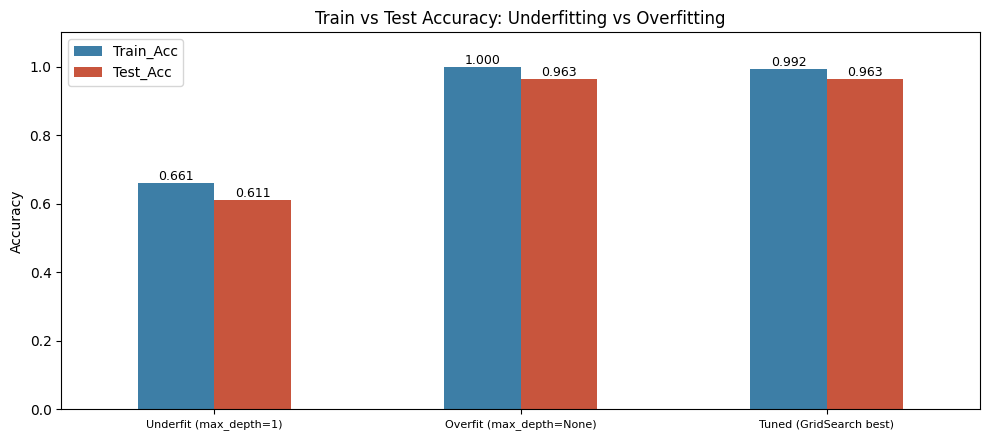

In [105]:
# Overfitting study: 3 Decision Tree variants
variants = {
    'Underfit (max_depth=1)': DecisionTreeClassifier(max_depth=1, random_state=42),
    'Overfit (max_depth=None)': DecisionTreeClassifier(max_depth=None, random_state=42),
    'Tuned (GridSearch best)': clone(w_best_dt),
}
fit_rows = []
for name, m in variants.items():
    m.fit(Xw_train_scaled, yw_train)
    tr = accuracy_score(yw_train, m.predict(Xw_train_scaled))
    te = accuracy_score(yw_test, m.predict(Xw_test_scaled))
    fit_rows.append({'Variant': name, 'Depth': m.get_depth(), 'Train_Acc': tr, 'Test_Acc': te, 'Gap': tr - te})
fit_df = pd.DataFrame(fit_rows).set_index('Variant')
print('Tuned params:', w_dt_grid.best_params_)
display(fit_df.round(4))

ax = fit_df[['Train_Acc', 'Test_Acc']].plot(kind='bar', figsize=(10, 4.5), color=['#3D7EA6', '#C8553D'])
for c in ax.containers:
    ax.bar_label(c, fmt='%.3f', fontsize=9)
ax.set_ylim(0, 1.1); ax.set_ylabel('Accuracy'); ax.set_xlabel('')
ax.set_title('Train vs Test Accuracy: Underfitting vs Overfitting')
plt.xticks(rotation=0, fontsize=8); plt.tight_layout(); plt.show()

### ✍️ Underfitting vs Overfitting

**[Your Answer]:**
1. Which variant underfits? How can you tell from the train/test accuracy?
2. Which variant overfits? What is the gap between train and test accuracy?
3. How does the tuned model sit between these two extremes?


*Write your answers here:*

1. **`max_depth=1` underfits.** Train accuracy is **0.661** and test accuracy **0.611**: *both* are low and close together. That pattern (poor everywhere, small gap) is the signature of high bias. A single split can only make two groups, but there are three cultivars, so one class can never be predicted.

2. **`max_depth=None` overfits.** Train accuracy is **1.000**: it memorised every training wine. Test accuracy is **0.963**, a gap of **0.037**. The gap is mild because the wine data is clean and well separated (the unconstrained tree only needed depth 4). On noisier data the gap grows a lot: in the synthetic "moons" plot below, an unlimited tree scores 1.00 on train but only 0.875 on test.

3. **The tuned tree (depth 3, min_samples_split=5) sits in the sweet spot.** Train accuracy is **0.992**, test **0.963**, the **smallest gap (0.029)**. It gets the same test accuracy as the unlimited tree with a simpler model, because it stops before memorising the last few training points. When two models generalise equally well, prefer the simpler one: it's more likely to hold up on new data.

---
## Indicative Mark Summary

> **Reminder:** These marks are for self-assessment only. They do not count towards your final grade.

| Section | Topic | Marks |
|---------|-------|-------|
| **Part 1** | | **55** |
| Stage 1 | Data Loading | 3 |
| Stage 2 | Data Understanding + Interpretation | 8 |
| Stage 3 | Preprocessing | 7 |
| Helper + Tutorial | Evaluation Function, GridSearchCV Walkthrough | 0 |
| Stage 4 | Model Training and Tuning (4 models) | 23 |
| Stage 5 | Model Comparison + Feature Importance | 9 |
| Stage 6 | Final Model Selection | 5 |
| **Part 2** | | **45** |
| Stage 1 | Data Loading | 2 |
| Stage 2 | Data Understanding + Interpretation | 6 |
| Stage 3 | Preprocessing | 4 |
| Stage 4 | Model Training and Tuning (5 models, incl. MLP) | 20 |
| Stage 5 | Model Comparison | 8 |
| Stage 6 | Final Recommendation | 5 |
| | **Total** | **100** |

---
*End of Practice Assignment*
